<a href="https://colab.research.google.com/github/sdow-docs/Data_Analytics/blob/data_cleaning/Sarah_Colab_Works.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [332]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [333]:
df = pd.read_csv('social_media_vs_productivity.csv')

In [334]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  object 
 2   job_type                        30000 non-null  object 
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  object 
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              

In [335]:
df = df.dropna()

This is still a very large dataset. I want to only use a sample size of 15% for analysis.

In [336]:
df = df.sample(frac=0.015, random_state=42)

In [337]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 256 entries, 3661 to 1911
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             256 non-null    int64  
 1   gender                          256 non-null    object 
 2   job_type                        256 non-null    object 
 3   daily_social_media_time         256 non-null    float64
 4   social_platform_preference      256 non-null    object 
 5   number_of_notifications         256 non-null    int64  
 6   work_hours_per_day              256 non-null    float64
 7   perceived_productivity_score    256 non-null    float64
 8   actual_productivity_score       256 non-null    float64
 9   stress_level                    256 non-null    float64
 10  sleep_hours                     256 non-null    float64
 11  screen_time_before_sleep        256 non-null    float64
 12  breaks_during_work              256 n

In [338]:
bins = [0, 18, 30, 45, 60, 100]

labels = ['Under 18', '18-30', '31-45', '46-60', 'Over 60']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)
df[['age', 'age_group']].head(10)

,age,age_group
3661,36,31-45
13279,21,18-30
29735,23,18-30
14700,36,31-45
7091,41,31-45
7137,38,31-45
1738,47,46-60
21709,18,Under 18
8927,58,46-60
19381,33,31-45


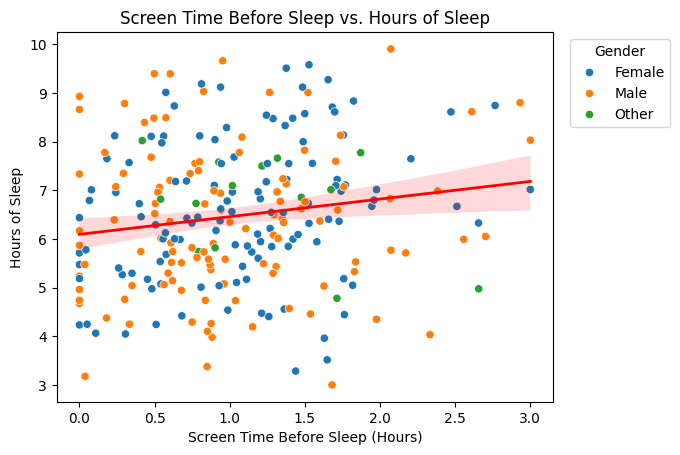

In [348]:
sns.scatterplot(
      data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',hue='gender')

sns.regplot(
    data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',
    scatter=False,
    color='red',
    line_kws={'linewidth': 2}
)


plt.title('Screen Time Before Sleep vs. Hours of Sleep')
plt.xlabel('Screen Time Before Sleep (Hours)')
plt.ylabel('Hours of Sleep')
plt.legend(title='Gender')
plt.legend(title='Gender', loc='upper left', bbox_to_anchor=(1.02, 1))

plt.show()

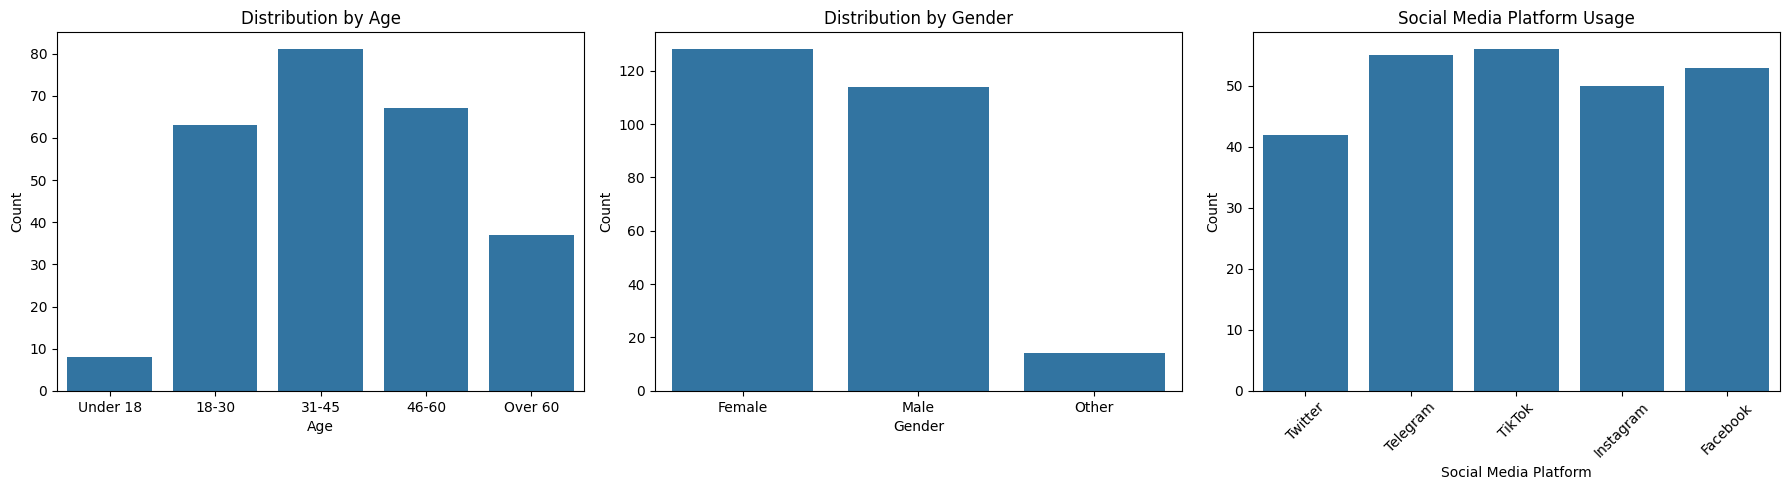

In [341]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age
sns.countplot(data=df, x='age_group', ax=axes[0])
axes[0].set_title('Distribution by Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# Gender
sns.countplot(data=df, x='gender', ax=axes[1])
axes[1].set_title('Distribution by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')

# Social Media Platform
sns.countplot(data=df, x='social_platform_preference', ax=axes[2])
axes[2].set_title('Social Media Platform Usage')
axes[2].set_xlabel('Social Media Platform')
axes[2].set_ylabel('Count')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

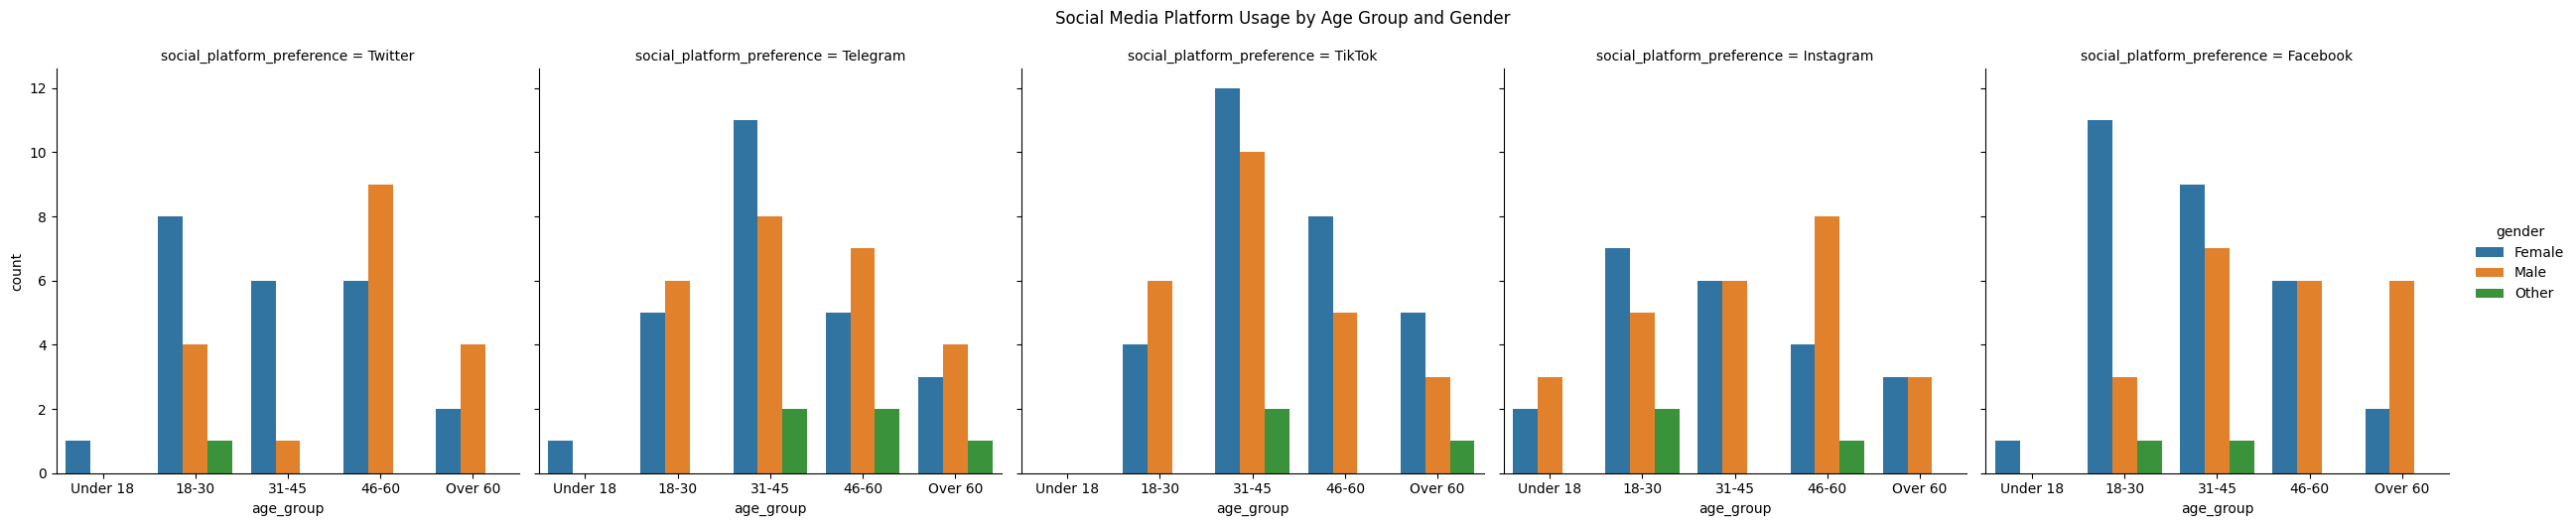

In [350]:
sns.catplot(
    data=df,
    x='age_group',
    hue='gender',
    col='social_platform_preference',
    kind='count',
    height=5,
    aspect=1
)

plt.suptitle('Social Media Platform Usage by Age Group and Gender', y=1.05)

plt.show()

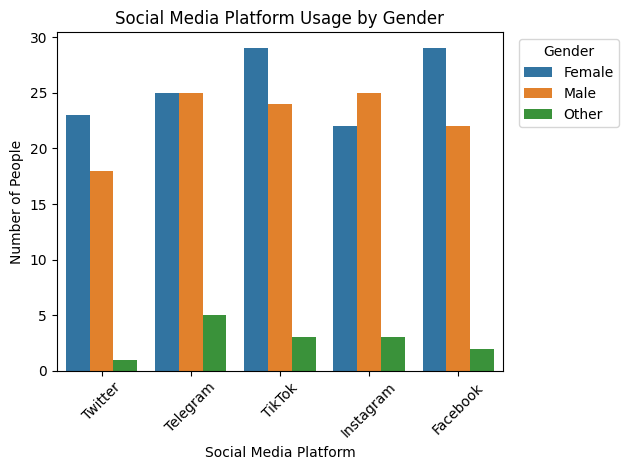

In [352]:
sns.countplot(
    data=df,
    x='social_platform_preference',
    hue='gender'
)

plt.title('Social Media Platform Usage by Gender')
plt.xlabel('Social Media Platform')
plt.ylabel('Number of People')
plt.legend(title='Gender')
plt.xticks(rotation=45)
plt.legend(title='Gender', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()